# Predicción de resistencia antimicrobiana a partir de espectros MALDI-TOF

### Primera y Segunda Pre-Sustentación · Inteligencia Artificial I · 2026-2
### Universidad Industrial de Santander

| | |
|---|---|
| **Autor** | Juan David Lipez Guevara, 2223102 |
| **Objetivo** | Predecir la resistencia a oxacilina de *Staphylococcus aureus* desde su espectro de masas, sin esperar el antibiograma. |
| **Dataset** | DRIAMS ([Kaggle](https://www.kaggle.com/datasets/drscarlat/driams), [paper](https://doi.org/10.1038/s41591-021-01619-9)) |

---
# 1. Motivación y descripción del problema

## 1.1 El problema

La resistencia antimicrobiana causó 1,27 millones de muertes directas en 2019 y se asoció a otras
4,95 millones (Murray et al., *The Lancet*, 2022). La OMS la ubica entre las diez principales
amenazas a la salud pública.

El caso concreto es el MRSA, la infección hospitalaria resistente más frecuente: la mortalidad de
una bacteriemia por MRSA casi duplica la de su equivalente sensible.

## 1.2 Cómo se resuelve hoy

| Paso | Método | Tiempo |
|---|---|---|
| Identificar la especie | MALDI-TOF MS | minutos |
| Determinar la resistencia | Antibiograma por cultivo | 24 a 72 horas |

En esas 24 a 72 horas el paciente recibe terapia empírica de amplio espectro, que es uno de los
motores de la resistencia que se quiere contener.

## 1.3 Qué aporta el modelo

Hipótesis: el espectro del primer paso ya contiene la información de resistencia. Sustento
biológico: el gen `mecA` codifica la proteína PBP2a y viaja en el cassette SCC*mec*, que altera el
proteoma, y el proteoma es lo que mide MALDI-TOF.

Si el modelo lee esa señal, la resistencia se estima en minutos, sobre un espectro ya capturado y
sin insumos adicionales.

## 1.4 Quién usaría la solución

| Usuario | Uso |
|---|---|
| Microbiólogo clínico | Priorizar qué muestras confirmar por cultivo |
| Médico tratante | Orientar la terapia empírica en las primeras horas |
| Comité de control de infecciones | Detectar portadores y brotes con menor demora |

## 1.5 Contexto local

Colombia reporta prevalencias de MRSA cercanas al 40% en infección hospitalaria (GREBO, Bogotá),
por encima del hospital suizo de DRIAMS. Los MALDI-TOF ya están instalados en los laboratorios de
referencia del país, así que esto no exige equipos nuevos, solo software.

---
# 2. El dataset

## 2.1 Qué es DRIAMS

Espectros MALDI-TOF vinculados a perfiles de resistencia confirmados por antibiograma. Borgwardt
Lab, ETH Zürich, *Nature Medicine* 2022.

| Sitio | Institución | Años | Muestras |
|---|---|---|---|
| DRIAMS-A | Hospital Universitario de Basilea | 2015 a 2018 | 111.257 |
| DRIAMS-B | Hospital Cantonal de Aarau | 2018 | 5.897 |
| DRIAMS-C | Hospital Cantonal de Friburgo | 2018 | 4.696 |
| DRIAMS-D | Laboratorio Viollier | 2018 | 10.436 |
| | | **Total** | **132.286** |

Se usa DRIAMS-A, el único sitio con los cuatro años.

## 2.2 Estructura de los archivos

```
DRIAMS-A/
├── id/<año>/<año>_clean.csv       metadata: especie y antibióticos (R/S/I/-)
├── id/<año>/<año>_strat.csv       metadata extendida: fecha, estación, paciente
└── binned_6000/<año>/<uuid>.txt   un archivo por espectro
```

Cada espectro trae 6.000 bins ya preprocesados, de 3 Da de ancho:

$$m/z = 2000 + 3 \times \text{bin\_index}$$

Cubren de 2.000 a 20.000 Da, la ventana de la huella de las proteínas ribosomales.

## 2.3 Elección del par objetivo

Cada columna de antibiótico es una prueba independiente hecha solo sobre algunas muestras, así que
el par especie-antibiótico define la tarea. La dispersión se mide en 4.2.

Se eligió *S. aureus* con oxacilina porque es el MRSA, el resistente de mayor peso hospitalario;
porque la etiqueta refleja un mecanismo biológico medido (`mecA`); y porque es caso de referencia
del paper, con AUROC publicado cercano a 0,80.

Se descartó *S. epidermidis*: tenía conteos idénticos de 3006 R y 1255 S en cinco antibióticos
distintos, señal de etiquetas propagadas por regla experta del laboratorio.

---
# 3. Carga de los datos crudos

`prepare_data.py` extrae del zip las 6.994 muestras de *S. aureus* sin filtrar ni codificar. Toda
la limpieza ocurre acá. En Colab basta subir los dos archivos a Drive y ajustar `RUTA`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["figure.dpi"] = 110

import os

if os.path.exists("/content"):                  # estamos en Colab
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA = "/content/drive/MyDrive/course-IA1/data"
else:                                           # en local
    RUTA = "data"

crudo = pd.read_csv(f"{RUTA}/saureus_raw.csv", low_memory=False)   # metadata sin tocar
Xc    = np.load(f"{RUTA}/saureus_raw.npy")                         # espectros, filas alineadas
mz    = 2000 + 3 * np.arange(Xc.shape[1])                          # eje de masa/carga en Da

assert len(crudo) == len(Xc), "el csv y la matriz no tienen el mismo numero de filas"

print(f"metadata cruda : {crudo.shape}")
print(f"espectros      : {Xc.shape}  ({Xc.nbytes/1e6:.0f} MB, {Xc.dtype})")
print(f"rango m/z      : {mz[0]:,} a {mz[-1]:,} Da")

Mounted at /content/drive
metadata cruda : (6994, 98)
espectros      : (6994, 6000)  (168 MB, float32)
rango m/z      : 2,000 a 19,997 Da


---
# 4. Limpieza y formato

## 4.1 Columnas espurias

Los CSV de origen guardaron el índice de pandas como columna, con prefijo `Unnamed:`.

In [2]:
espurias = [c for c in crudo.columns if c.startswith("Unnamed:")]
print("columnas espurias encontradas:")
for c in espurias:
    print(f"  {c:16s} ejemplo: {crudo[c].dropna().iloc[0]}")

crudo = crudo.drop(columns=espurias)
print(f"\ncolumnas: {len(crudo.columns) + len(espurias)} antes, {len(crudo.columns)} despues")

columnas espurias encontradas:
  Unnamed: 0.1     ejemplo: 6.0
  Unnamed: 0       ejemplo: 6.0

columnas: 98 antes, 96 despues


## 4.2 Qué tan dispersa es la matriz de etiquetas

Cada antibiótico es una prueba ordenada solo para algunas muestras. Celda vacía y guion significan
que no se hizo.

In [3]:
NO_ANTIBIOTICO = ["code", "species", "laboratory_species", "year",
                  "acquisition_date", "acquisition_time", "workstation", "patient_no", "case_no"]
antibioticos = [c for c in crudo.columns if c not in NO_ANTIBIOTICO]

conteo = (crudo[antibioticos].fillna("(vacio)").astype(str)
          .apply(pd.Series.value_counts).sum(axis=1).sort_values(ascending=False))
celdas = len(crudo) * len(antibioticos)

print(f"{len(antibioticos)} columnas de antibiótico x {len(crudo)} muestras = {celdas:,} celdas\n")
for valor, n in conteo.items():
    print(f"  {valor:12s} {int(n):7,}  {100*n/celdas:5.1f}%")

sin_dato = conteo.get("(vacio)", 0) + conteo.get("-", 0)
print(f"\nsin etiqueta utilizable: {100*sin_dato/celdas:.1f}% de las celdas")

87 columnas de antibiótico x 6994 muestras = 608,478 celdas

  (vacio)      301,326   49.5%
  -            215,033   35.3%
  S             77,398   12.7%
  R             14,187    2.3%
  R(1), S(1)       389    0.1%
  I                117    0.0%
  I(1), S(1)        18    0.0%
  R(1), I(1)         8    0.0%
  R(1), I(1), S(1)       2    0.0%

sin etiqueta utilizable: 84.9% de las celdas


## 4.3 Estado de la columna objetivo

Se repite la cuenta sobre la única columna que interesa, `Oxacillin`.

In [4]:
print(crudo.Oxacillin.value_counts(dropna=False).to_string())

Oxacillin
NaN           3189
S             3064
R              726
-               14
R(1), S(1)       1


Tres categorías no sirven como etiqueta: celda vacía (nunca se registró), guion (no se testeó) y
`R(1), S(1)` (dos mediciones que se contradicen). No hay casos `I` de resistencia intermedia.

## 4.4 Filtrado

Se conservan las mediciones limpias, `R` o `S`. La misma máscara se aplica a los espectros para que
las filas sigan correspondiéndose.

In [5]:
valido = crudo.Oxacillin.isin(["R", "S"])

print("filtrado paso a paso:")
print(f"  DRIAMS-A completo                      111,257")
print(f"  filtrar species == 'S. aureus'         {len(crudo):7,}")
for categoria in crudo.loc[~valido, "Oxacillin"].fillna("(vacio)").value_counts().items():
    print(f"  descartar Oxacillin == '{categoria[0]}'".ljust(41) + f"-{categoria[1]:6,}")
print(f"  {'conjunto de trabajo'.ljust(39)}{valido.sum():7,}")

meta = crudo.loc[valido].reset_index(drop=True)
X    = Xc[valido.to_numpy()]

print(f"\nmeta {meta.shape}   X {X.shape}")

filtrado paso a paso:
  DRIAMS-A completo                      111,257
  filtrar species == 'S. aureus'           6,994
  descartar Oxacillin == '(vacio)'       - 3,189
  descartar Oxacillin == '-'             -    14
  descartar Oxacillin == 'R(1), S(1)'    -     1
  conjunto de trabajo                      3,790

meta (3790, 96)   X (3790, 6000)


## 4.5 Codificación de la etiqueta y selección de columnas

De las 96 columnas se conservan 7: las que identifican la muestra, más la etiqueta.

Se descartan las de antibióticos, que ya cumplieron su función al definir el objetivo, y las de
fecha y hora: registran cuándo se procesó la muestra, no la bacteria. Un modelo que las viera
podría aprender que cierto turno concentra más resistencia, que es calendario y no biología.

In [6]:
meta["label"] = (meta.Oxacillin == "R").astype(int)

# sin columnas de fecha ni hora: no describen la bacteria, solo cuando se proceso la muestra
COLUMNAS = ["code", "species", "workstation", "patient_no", "case_no", "Oxacillin", "label"]
temporales = [c for c in meta.columns if c in ("year", "acquisition_date", "acquisition_time")]

print("columnas temporales descartadas:", ", ".join(temporales))
meta = meta[COLUMNAS]

print()
print(meta.label.value_counts().rename({0: "S (susceptible)", 1: "R (resistente)"}).to_string())
print(f"\nprevalencia de resistencia: {100*meta.label.mean():.1f}%")
print(f"columnas conservadas: {len(meta.columns)} de {len(crudo.columns)}")

columnas temporales descartadas: year, acquisition_date, acquisition_time

label
S (susceptible)    3064
R (resistente)      726

prevalencia de resistencia: 19.2%
columnas conservadas: 7 de 96


## 4.6 Verificación

Cada `assert` falla de forma ruidosa si el supuesto no se cumple.

In [7]:
assert len(meta) == len(X),                    "meta y X quedaron desalineados"
assert not meta.code.duplicated().any(),       "hay codes duplicados"
assert meta.notna().all().all(),               "quedaron nulos en la metadata"
assert meta.label.isin([0, 1]).all(),          "la etiqueta tiene valores fuera de {0,1}"
assert not np.isnan(X).any(),                  "la matriz de espectros tiene NaN"
assert (X >= 0).all(),                         "hay intensidades negativas"
assert X.shape[1] == 6000,                     "algun espectro no tiene 6000 bins"
assert meta.species.nunique() == 1,            "se colo mas de una especie"

print("verificaciones superadas")
print(f"conjunto final: {len(meta)} muestras, {X.shape[1]} bins, "
      f"{meta.label.sum()} resistentes y {(1-meta.label).sum()} susceptibles")

verificaciones superadas
conjunto final: 3790 muestras, 6000 bins, 726 resistentes y 3064 susceptibles


---
# 5. Exploración de la estructura

## 5.1 Primeras filas

In [8]:
meta.head()

,code,species,workstation,patient_no,case_no,Oxacillin,label
0,49eceea6-f184-4ed2-9cf6-e6d411c47f85,Staphylococcus aureus,Blood,19383_2015_Staphylococcus aureus,2386_2015_Staphylococcus aureus,S,0
1,e2944974-79cf-4457-b042-f56a42fb717c,Staphylococcus aureus,DeepTissue,478_2015_Staphylococcus aureus,2294_2015_Staphylococcus aureus,R,1
2,6cab683a-cc5f-47c6-8b10-18e117ccf932,Staphylococcus aureus,Blood,13651_2015_Staphylococcus aureus,3538_2015_Staphylococcus aureus,S,0
3,a2167137-4f68-4034-8376-dd25936ad094,Staphylococcus aureus,Respiratory,2179_2015_Staphylococcus aureus,2463_2015_Staphylococcus aureus,S,0
4,d5bd8e2b-8fcb-4151-8856-c82390f5c4d2,Staphylococcus aureus,Respiratory,1519_2015_Staphylococcus aureus,93_2015_Staphylococcus aureus,S,0


## 5.2 Columnas, tipos y nulos

In [9]:
print(f"{len(meta.columns)} columnas:\n")
for c in meta.columns:
    print(f"  {c:20s} {str(meta[c].dtype):10s} nulos={meta[c].isna().sum():4d}  únicos={meta[c].nunique()}")

7 columnas:

  code                 object     nulos=   0  únicos=3790
  species              object     nulos=   0  únicos=1
  workstation          object     nulos=   0  únicos=7
  patient_no           object     nulos=   0  únicos=1841
  case_no              object     nulos=   0  únicos=2018
  Oxacillin            object     nulos=   0  únicos=2
  label                int64      nulos=   0  únicos=2


## 5.3 Información general

In [10]:
meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3790 entries, 0 to 3789
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   code         3790 non-null   object
 1   species      3790 non-null   object
 2   workstation  3790 non-null   object
 3   patient_no   3790 non-null   object
 4   case_no      3790 non-null   object
 5   Oxacillin    3790 non-null   object
 6   label        3790 non-null   int64 
dtypes: int64(1), object(6)
memory usage: 207.4+ KB


## 5.4 Resumen estadístico

In [11]:
meta.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
code,3790,3790,49eceea6-f184-4ed2-9cf6-e6d411c47f85,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
species,3790,1,Staphylococcus aureus,3790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
workstation,3790,7,DeepTissue,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_no,3790,1841,33585_2017_Staphylococcus aureus,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
case_no,3790,2018,32479_2017_Staphylococcus aureus,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oxacillin,3790,2,S,3064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,3790.0,NaN,NaN,NaN,0.191557,0.393578,0.0,0.0,0.0,0.0,1.0


---
# 6. Variables de resumen por espectro

Un histograma por bin daría 6.000 gráficas, y el IQR de un bin aislado no describe nada: los bins
son puntos de una misma curva, no variables independientes.

Se construyen seis variables que resumen cada espectro. Una intensidad máxima anómala o muy pocos
picos indican medición defectuosa, así que detectarlas es control de calidad.

In [12]:
# umbral de pico: 3 desviaciones sobre la media del propio espectro
umbral = X.mean(axis=1, keepdims=True) + 3 * X.std(axis=1, keepdims=True)

# variables continuas, aptas para histograma e IQR
num = pd.DataFrame({
    "intensidad_media" : X.mean(axis=1),
    "intensidad_std"   : X.std(axis=1),
    "intensidad_max"   : X.max(axis=1),
    "energia_total"    : X.sum(axis=1),
    "n_picos"          : (X > umbral).sum(axis=1),
})

# variable categorica; la seccion 7.2 explica por que no entra en el IQR
meta["mz_pico_dominante"] = mz[X.argmax(axis=1)]

num.describe().T

,count,mean,std,min,25%,50%,75%,max
intensidad_media,3790.0,0.000225,0.000011,0.000196,0.000216,0.000224,0.000231,0.000273
intensidad_std,3790.0,0.000602,0.000120,0.000227,0.000503,0.000599,0.000687,0.001214
intensidad_max,3790.0,0.010751,0.003484,0.003006,0.008173,0.010241,0.012534,0.037398
energia_total,3790.0,1.350441,0.064708,1.177421,1.298664,1.342989,1.384203,1.640496
n_picos,3790.0,115.012929,13.718952,44.000000,108.000000,116.000000,124.000000,173.000000


---
# 7. Detección de outliers con el rango intercuartílico

Se aplica el criterio de Tukey sobre cada variable continua de resumen:

$$IQR = Q_3 - Q_1 \qquad\qquad x < Q_1 - 1{,}5 \cdot IQR \quad \text{o} \quad x > Q_3 + 1{,}5 \cdot IQR$$

In [13]:
def limites_iqr(serie):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

reporte = []
for col in num.columns:
    li, ls = limites_iqr(num[col])
    fuera = (num[col] < li) | (num[col] > ls)
    reporte.append({
        "variable": col,
        "limite_inferior": li,
        "limite_superior": ls,
        "n_outliers": int(fuera.sum()),
        "%": round(100 * fuera.mean(), 2),
    })

reporte = pd.DataFrame(reporte)
reporte

,variable,limite_inferior,limite_superior,n_outliers,%
0,intensidad_media,0.000195,0.000252,77,2.03
1,intensidad_std,0.000229,0.000961,19,0.50
2,intensidad_max,0.001631,0.019075,86,2.27
3,energia_total,1.170357,1.512510,77,2.03
4,n_picos,84.000000,148.000000,123,3.25


In [14]:
# cuantos espectros son outlier en al menos una variable
mascara = pd.DataFrame({c: ((num[c] < limites_iqr(num[c])[0]) | (num[c] > limites_iqr(num[c])[1]))
                        for c in num.columns})
num["n_criterios_outlier"] = mascara.sum(axis=1)
es_outlier = num["n_criterios_outlier"] > 0

print(f"outlier en al menos una variable : {es_outlier.sum()} ({100*es_outlier.mean():.1f}%)")
print(f"outlier en tres o mas variables  : {(num['n_criterios_outlier'] >= 3).sum()}")
print()
print("distribucion por clase (%):")
print(pd.crosstab(es_outlier, meta.Oxacillin, normalize='columns').mul(100).round(1))

outlier en al menos una variable : 233 (6.1%)
outlier en tres o mas variables  : 26

distribucion por clase (%):
Oxacillin               R     S
n_criterios_outlier            
False                93.4  94.0
True                  6.6   6.0


## 7.2 Una variable que no admite análisis IQR

`mz_pico_dominante` marcó cerca del 45% de los espectros como atípicos, frente a menos del 4% de
las otras cinco. Eso señala un problema en el criterio, no en los datos.

In [15]:
from scipy import stats

dom = meta["mz_pico_dominante"]
Q1, Q3 = dom.quantile(0.25), dom.quantile(0.75)

print(f"valores distintos : {dom.nunique()} de {len(mz)} bins posibles")
print(f"Q1 = {Q1:,.0f} Da   Q3 = {Q3:,.0f} Da   IQR = {Q3-Q1:,.0f} Da")
print(f"rango total       : {mz[-1]-mz[0]:,} Da")
print()
print("masas mas frecuentes del pico dominante:")
for m, n in dom.value_counts().head(5).items():
    print(f"  m/z {m:6,.0f} Da : {n:5d} espectros ({100*n/len(dom):5.1f}%)")
print()
print("asimetria y tasa de outliers por variable:")
for c in list(num.columns.drop("n_criterios_outlier")) + ["mz_pico_dominante"]:
    serie = num[c] if c in num.columns else dom
    q1, q3 = serie.quantile([0.25, 0.75]); iqr = q3 - q1
    fuera = ((serie < q1 - 1.5*iqr) | (serie > q3 + 1.5*iqr)).mean() * 100
    print(f"  {c:20s} asimetria={stats.skew(serie):6.2f}   outliers={fuera:5.1f}%")

valores distintos : 130 de 6000 bins posibles
Q1 = 4,301 Da   Q3 = 4,307 Da   IQR = 6 Da
rango total       : 17,997 Da

masas mas frecuentes del pico dominante:
  m/z  4,307 Da :  1032 espectros ( 27.2%)
  m/z  4,304 Da :   860 espectros ( 22.7%)
  m/z  3,443 Da :   201 espectros (  5.3%)
  m/z  4,814 Da :   194 espectros (  5.1%)
  m/z  3,005 Da :   180 espectros (  4.7%)

asimetria y tasa de outliers por variable:
  intensidad_media     asimetria=  0.88   outliers=  2.0%
  intensidad_std       asimetria=  0.44   outliers=  0.5%
  intensidad_max       asimetria=  1.44   outliers=  2.3%
  energia_total        asimetria=  0.88   outliers=  2.0%
  n_picos              asimetria= -0.57   outliers=  3.2%
  mz_pico_dominante    asimetria=  0.62   outliers= 44.5%


Toma pocas decenas de valores de 6.000 posibles, y casi la mitad de los espectros comparten el pico
dominante cercano a 4.305 Da. El IQR colapsa a unos pocos Da sobre un rango de 18.000, así que el
criterio marca como atípico casi todo lo que no caiga en la moda.

Es una variable **categórica codificada como número**: indica cuál proteína domina el espectro, no
una cantidad sobre un continuo. Tukey supone distribución continua y unimodal; esta es discreta y
multimodal, así que pasa a tratarse como categórica.

---
# 8. Visualización

## 8.1 Gráficos de torta para las variables categóricas

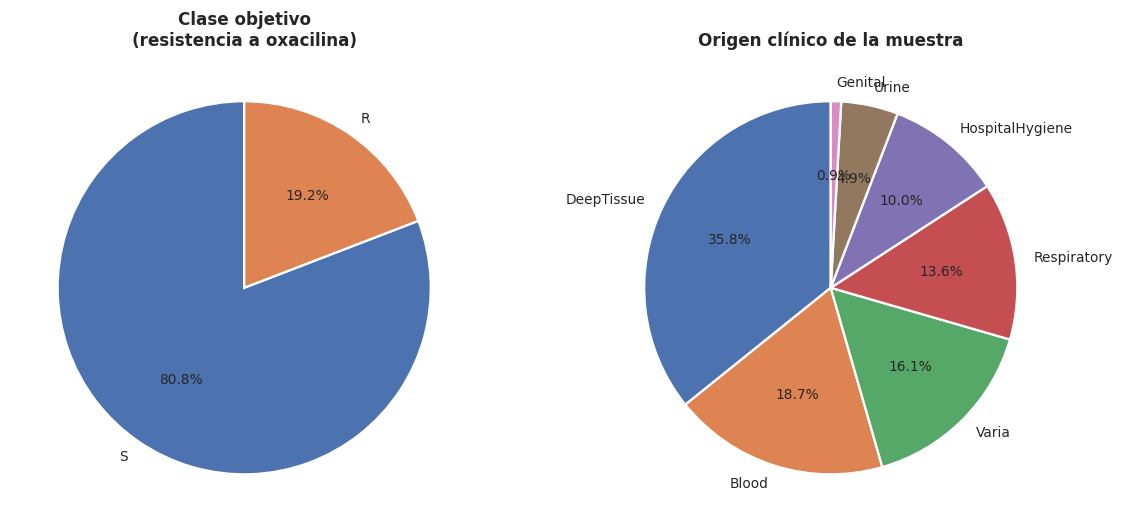

In [16]:
cats = ["Oxacillin", "workstation"]
titulos = ["Clase objetivo\n(resistencia a oxacilina)", "Origen clínico de la muestra"]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col, tit in zip(axes, cats, titulos):
    vc = meta[col].value_counts()
    ax.pie(vc, labels=vc.index, autopct="%1.1f%%", startangle=90,
           wedgeprops=dict(edgecolor="white", linewidth=1.5),
           textprops=dict(fontsize=9))
    ax.set_title(tit, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

El pico dominante, reclasificado en la sección 7.2, va en barras.

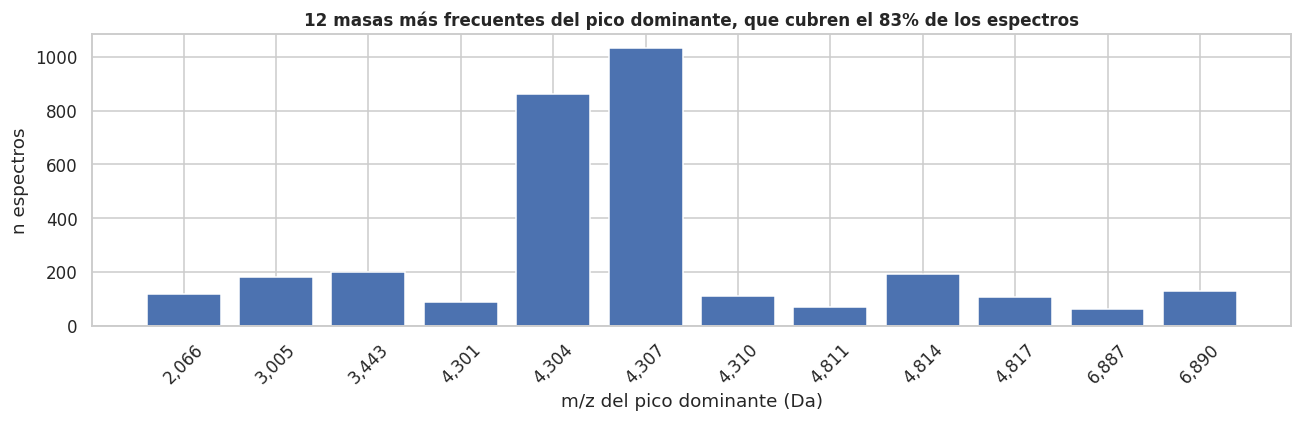

In [17]:
top = meta["mz_pico_dominante"].value_counts().head(12).sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar([f"{int(m):,}" for m in top.index], top.values, color="#4C72B0", edgecolor="white")
ax.set_xlabel("m/z del pico dominante (Da)"); ax.set_ylabel("n espectros")
ax.set_title("12 masas más frecuentes del pico dominante, "
             f"que cubren el {100*top.sum()/len(meta):.0f}% de los espectros",
             fontweight="bold", fontsize=11)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 8.2 Histogramas de las variables continuas

La línea roja punteada marca los límites del IQR.

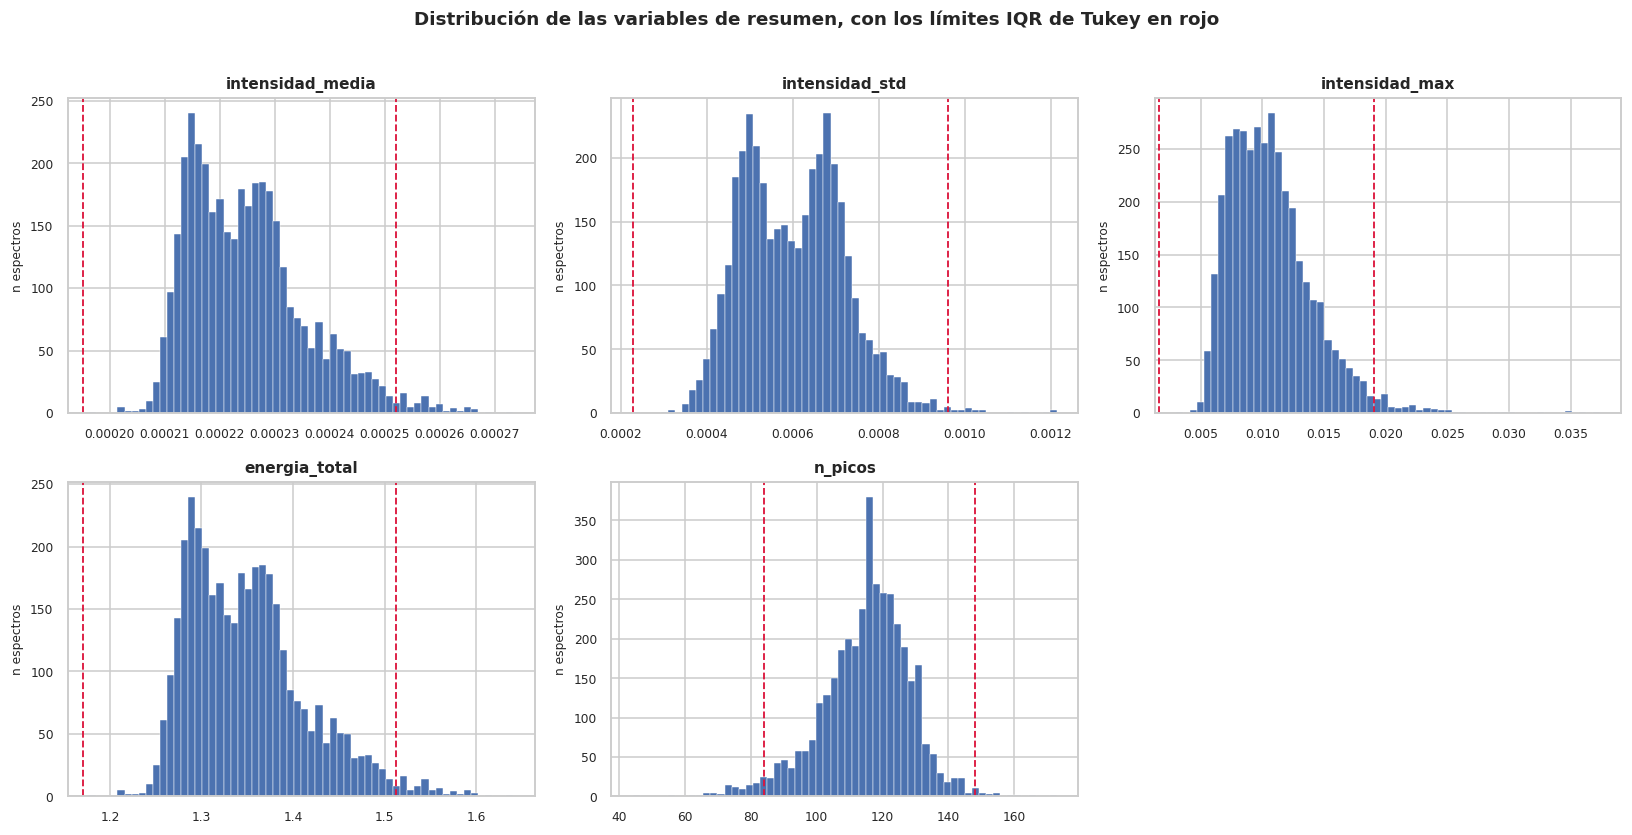

In [18]:
cols = [c for c in num.columns if c != "n_criterios_outlier"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
axes.ravel()[-1].axis("off")          # solo hay 5 variables continuas

for ax, col in zip(axes.ravel(), cols):
    ax.hist(num[col], bins=60, color="#4C72B0", edgecolor="white", linewidth=0.3)
    li, ls = limites_iqr(num[col])
    for lim in (li, ls):
        ax.axvline(lim, color="crimson", linestyle="--", linewidth=1.2)
    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.set_ylabel("n espectros", fontsize=8)
    ax.tick_params(labelsize=8)

fig.suptitle("Distribución de las variables de resumen, con los límites IQR de Tukey en rojo",
             fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 8.3 Dispersión de los outliers

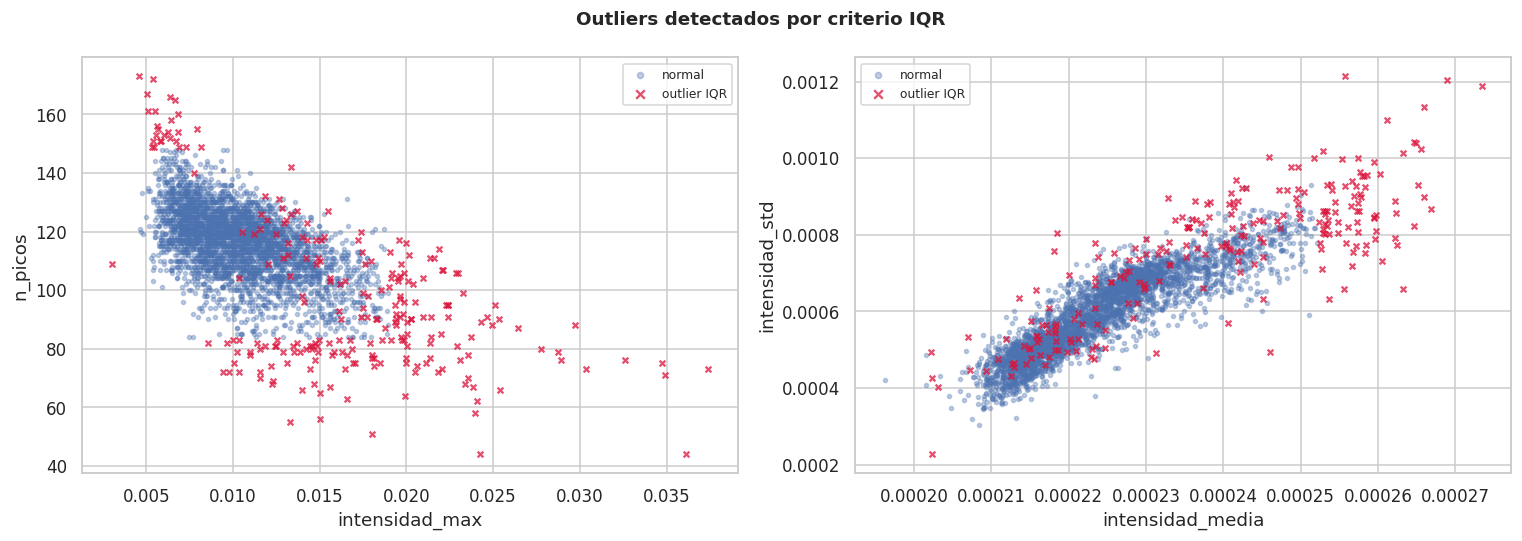

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (x, y) in zip(axes, [("intensidad_max", "n_picos"),
                             ("intensidad_media", "intensidad_std")]):
    ax.scatter(num.loc[~es_outlier, x], num.loc[~es_outlier, y],
               s=7, alpha=0.35, color="#4C72B0", label="normal")
    ax.scatter(num.loc[es_outlier, x], num.loc[es_outlier, y],
               s=14, alpha=0.75, color="crimson", marker="x", label="outlier IQR")
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.legend(fontsize=8, markerscale=1.5)

fig.suptitle("Outliers detectados por criterio IQR", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

---
# 9. Composición del conjunto

Dos cruces entre la metadata y la etiqueta cambian la lectura de las cifras anteriores.

## 9.1 Origen clínico de la muestra

In [20]:
tabla = (meta.groupby("workstation")
             .agg(n=("label", "size"), resistentes=("label", "sum"))
             .assign(pct_R=lambda d: (100 * d.resistentes / d.n).round(1))
             .sort_values("n", ascending=False))

h = meta[meta.workstation == "HospitalHygiene"]
print(tabla.to_string())
print()
print(f"HospitalHygiene aporta el {100*len(h)/len(meta):.1f}% de las muestras "
      f"y el {100*h.label.sum()/meta.label.sum():.1f}% de los casos resistentes.")
print()
print(f"Prevalencia sobre el total     : {100*meta.label.mean():.1f}% R")
print(f"Prevalencia sin HospitalHygiene: {100*meta[meta.workstation!='HospitalHygiene'].label.mean():.1f}% R")

                    n  resistentes  pct_R
workstation                              
DeepTissue       1356          155   11.4
Blood             708           28    4.0
Varia             609           73   12.0
Respiratory       517           48    9.3
HospitalHygiene   379          373   98.4
Urine             187           26   13.9
Genital            34           23   67.6

HospitalHygiene aporta el 10.0% de las muestras y el 51.4% de los casos resistentes.

Prevalencia sobre el total     : 19.2% R
Prevalencia sin HospitalHygiene: 10.3% R


`HospitalHygiene` es vigilancia epidemiológica: tamizaje activo de portadores de MRSA, así que por
diseño casi todo lo que pasa por ahí resulta resistente.

La prevalencia del conjunto completo es entonces un artefacto de muestreo; la clínica se obtiene
excluyendo esa estación.

## 9.2 Espectros por paciente

espectros           : 3790
pacientes únicos    : 1841
espectros/paciente  : 2.06
pacientes con >1    : 826   (máximo 23 espectros de un mismo paciente)
espectros afectados : 2775 (73.2% del total)

pacientes con etiquetas R y S mezcladas: 7


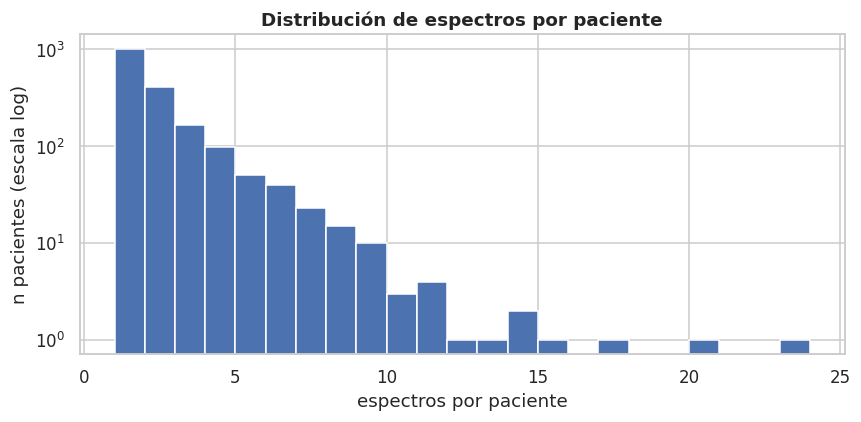

In [21]:
vc = meta.patient_no.value_counts()

print(f"espectros           : {len(meta)}")
print(f"pacientes únicos    : {meta.patient_no.nunique()}")
print(f"espectros/paciente  : {len(meta)/meta.patient_no.nunique():.2f}")
print(f"pacientes con >1    : {(vc>1).sum()}   (máximo {vc.max()} espectros de un mismo paciente)")
print(f"espectros afectados : {vc[vc>1].sum()} ({100*vc[vc>1].sum()/len(meta):.1f}% del total)")
print()
print(f"pacientes con etiquetas R y S mezcladas: {(meta.groupby('patient_no').label.nunique()>1).sum()}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vc.values, bins=range(1, vc.max()+2), color="#4C72B0", edgecolor="white")
ax.set_yscale("log")
ax.set_xlabel("espectros por paciente"); ax.set_ylabel("n pacientes (escala log)")
ax.set_title("Distribución de espectros por paciente", fontweight="bold")
plt.tight_layout(); plt.show()

Casi tres cuartas partes de los espectros vienen de pacientes con más de una muestra, y la etiqueta
es constante dentro de cada paciente salvo en unos pocos casos. No son observaciones independientes
sino pacientes medidos varias veces.

---
# 10. Tarea a realizar

Clasificación binaria supervisada.

| | |
|---|---|
| Entrada `X` | Espectro MALDI-TOF, 6.000 bins entre 2.000 y 20.000 Da |
| Salida `y` | `1` resistente a oxacilina (MRSA), `0` susceptible |
| Muestras | 3.790 espectros, 1.841 pacientes |
| Balance | 726 R (19,2%), 3.064 S (80,8%) |

La etiqueta viene ya categorizada por los puntos de corte EUCAST. Predecir la concentración mínima
inhibitoria sería regresión; DRIAMS publica la categoría, así que es clasificación.

---
---
# SEGUNDA PRE-SUSTENTACIÓN

Continúa sobre `meta` y `X` de la primera entrega: 3.790 muestras, 6.000 bins. No se recarga ni se
limpia nada.

Particionado 80/20 · DecisionTree · RandomForest · SVM · CrossValidation · perceptrón multicapa ·
barplot comparativo.

---
# 11. Métricas de evaluación

Predecir siempre *susceptible* da 80,8% de accuracy sin aprender nada (sección 9), así que accuracy
sola no sirve. Se miden tres cosas:

| Métrica | Qué mide |
|---|---|
| `accuracy` | Aciertos totales |
| `tpr` | Resistentes detectados (sensibilidad) |
| `tnr` | Susceptibles detectados (especificidad) |

Para elegir hiperparámetros se usa el promedio de `tpr` y `tnr`.

In [22]:
from sklearn.metrics import *
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

SEMILLA = 42

# se parte de lo que dejo la primera entrega
y         = meta.label.to_numpy()
pacientes = meta.patient_no.to_numpy()

print(f"X {X.shape}   y {y.shape}   pacientes unicos {len(np.unique(pacientes))}")
print(f"clase 1 (R, resistente) : {y.sum():5d}  ({100*y.mean():.1f}%)")
print(f"clase 0 (S, susceptible): {(1-y).sum():5d}  ({100*(1-y.mean()):.1f}%)")
print(f"baseline de clase mayoritaria: {100*max(y.mean(), 1-y.mean()):.1f}% de accuracy")

# sensibilidad y especificidad
def tpr(est, X, y):
    p = est.predict(X)
    return np.mean(p[y == 1] == y[y == 1])

def tnr(est, X, y):
    p = est.predict(X)
    return np.mean(p[y == 0] == y[y == 0])

# promedio de las dos: un solo numero para comparar hiperparametros
def tpr_tnr(est, X, y):
    return (tpr(est, X, y) + tnr(est, X, y)) / 2

acc = make_scorer(accuracy_score)

X (3790, 6000)   y (3790,)   pacientes unicos 1841
clase 1 (R, resistente) :   726  (19.2%)
clase 0 (S, susceptible):  3064  (80.8%)
baseline de clase mayoritaria: 80.8% de accuracy


---
# 12. Particionado 80/20

El 74% de los espectros vienen de pacientes repetidos (sección 9.2), así que un split al azar deja
al mismo paciente en train y test y el modelo acierta reconociéndolo.

Se aplica `train_test_split` **a la lista de pacientes**, no a la de espectros.

In [23]:
# se parte la lista de pacientes, no la de espectros
pac_unicos = np.unique(pacientes)
pac_train, pac_test = train_test_split(pac_unicos, test_size=0.2, random_state=SEMILLA)

en_train = np.isin(pacientes, pac_train)
X_train, y_train = X[en_train],  y[en_train]
X_test,  y_test  = X[~en_train], y[~en_train]
pac_de_train     = pacientes[en_train]

print(f"pacientes : {len(pac_train)} train / {len(pac_test)} test")
print(f"espectros : {len(y_train)} train / {len(y_test)} test "
      f"({100*len(y_test)/len(y):.0f}% en test)")
print(f"pacientes compartidos entre train y test: {len(set(pac_train) & set(pac_test))}")
print(f"prevalencia R : train {100*y_train.mean():.1f}%   test {100*y_test.mean():.1f}%")

pacientes : 1472 train / 369 test
espectros : 3058 train / 732 test (19% en test)
pacientes compartidos entre train y test: 0
prevalencia R : train 19.2%   test 19.0%


## 12.1 Escalado

SVM y red neuronal dependen de la escala. `StandardScaler` ajustado solo con train. Árbol y bosque
no lo necesitan: parten por umbrales, no por distancias.

In [24]:
from sklearn.preprocessing import StandardScaler

escala = StandardScaler()
X_train_s = escala.fit_transform(X_train)     # se ajusta solo con train
X_test_s  = escala.transform(X_test)          # test solo se transforma

print(f"antes  : media {X_train.mean():7.3f}   desviacion {X_train.std():7.3f}")
print(f"despues: media {X_train_s.mean():7.3f}   desviacion {X_train_s.std():7.3f}")

antes  : media   0.000   desviacion   0.001
despues: media   0.000   desviacion   1.000


## 12.2 Los folds de CrossValidation

Mismo cuidado: `KFold` sobre los pacientes, traducido a índices de espectros.

In [25]:
# arma k folds con KFold sobre los pacientes y los traduce a indices de espectros
def folds_por_paciente(pac_del_conjunto, k, semilla=SEMILLA):
    unicos = np.unique(pac_del_conjunto)
    folds = []
    for idx_tr, idx_va in KFold(k, shuffle=True, random_state=semilla).split(unicos):
        en_tr = np.isin(pac_del_conjunto, unicos[idx_tr])
        folds.append((np.where(en_tr)[0], np.where(~en_tr)[0]))
    return folds

K = 5                                              # se justifica en la seccion 16
CV = folds_por_paciente(pac_de_train, K)

for i, (tr, va) in enumerate(CV, start=1):
    print(f"  fold {i}: {len(tr)} train / {len(va)} validacion   "
          f"({100*y_train[va].mean():.1f}% R en validacion)")

  fold 1: 2447 train / 611 validacion   (18.8% R en validacion)
  fold 2: 2441 train / 617 validacion   (16.9% R en validacion)
  fold 3: 2461 train / 597 validacion   (19.9% R en validacion)
  fold 4: 2420 train / 638 validacion   (18.8% R en validacion)
  fold 5: 2463 train / 595 validacion   (21.7% R en validacion)


---
# 13. DecisionTree · curva para `max_depth`

Profundidad baja, *underfitting*; profundidad alta, memoriza el ruido de los 6.000 bins.
Un `cross_val_score` por cada profundidad.

In [26]:
from sklearn.tree import DecisionTreeClassifier

# un cross_val_score por cada valor del hiperparametro; grafica train contra validacion
def curva(construir, valores, titulo, xlabel, datos_tr=None, log=False):
    Xf = X_train if datos_tr is None else datos_tr
    medias_va, desv_va, medias_tr = [], [], []

    for v in valores:
        est = construir(v)
        s_va = cross_val_score(est, Xf, y_train, cv=CV, scoring=tpr_tnr)
        medias_va.append(np.mean(s_va)); desv_va.append(np.std(s_va))
        est.fit(Xf, y_train)
        medias_tr.append(tpr_tnr(est, Xf, y_train))
        print(f"  {xlabel}={str(v):<8s} train={medias_tr[-1]:.3f}  "
              f"validacion={medias_va[-1]:.3f} (+/- {desv_va[-1]:.5f})")

    medias_va, desv_va = np.array(medias_va), np.array(desv_va)
    x = np.arange(len(valores)) if isinstance(valores[0], str) else np.array(valores)

    plt.figure(figsize=(9, 4.5))
    plt.plot(x, medias_tr, "o-", color="#4C72B0", label="entrenamiento")
    plt.plot(x, medias_va, "o-", color="crimson", label="validacion (CV)")
    plt.fill_between(x, medias_va - desv_va, medias_va + desv_va, alpha=0.15, color="crimson")
    if log: plt.xscale("log")
    if isinstance(valores[0], str): plt.xticks(x, valores)
    plt.xlabel(xlabel); plt.ylabel("promedio de tpr y tnr")
    plt.title(titulo, fontweight="bold", fontsize=11); plt.legend()
    plt.tight_layout(); plt.show()

    mejor = valores[int(np.argmax(medias_va))]
    print(f"\nmejor {xlabel}: {mejor}")
    return mejor

  max_depth=1        train=0.671  validacion=0.668 (+/- 0.03489)
  max_depth=2        train=0.736  validacion=0.707 (+/- 0.03414)
  max_depth=3        train=0.770  validacion=0.719 (+/- 0.02608)
  max_depth=5        train=0.843  validacion=0.737 (+/- 0.03701)
  max_depth=8        train=0.892  validacion=0.723 (+/- 0.02822)
  max_depth=12       train=0.977  validacion=0.710 (+/- 0.03322)
  max_depth=20       train=1.000  validacion=0.693 (+/- 0.03444)
  max_depth=30       train=1.000  validacion=0.695 (+/- 0.03747)


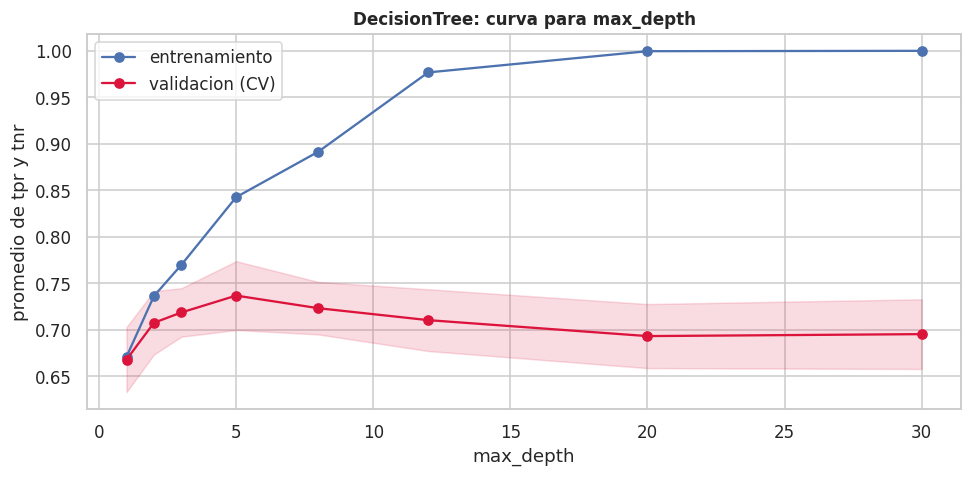


mejor max_depth: 5


In [27]:
PROFUNDIDADES = [1, 2, 3, 5, 8, 12, 20, 30]

mejor_depth = curva(
    lambda d: DecisionTreeClassifier(max_depth=d, class_weight="balanced",
                                     random_state=SEMILLA),
    PROFUNDIDADES, "DecisionTree: curva para max_depth", "max_depth")

---
# 14. RandomForest · curva para `n_estimators`

Más árboles no producen overfitting: cada uno se entrena aparte y el bosque promedia, así que
sumar árboles solo reduce la varianza del promedio. La curva verdadera sube y se aplana, nunca baja.

Por eso lo que salió merece comentario. La curva se mueve entre 0,58 y 0,62 **sin tendencia**, y el
bache de 10 árboles no puede ser real. Las diferencias entre valores (~0,01) son menores que la
desviación entre folds (~0,02), así que el máximo no se distingue del azar.

El criterio se queda con **5 árboles**. Eso no dice que 5 sea mejor que 200: dice que con esta curva
no se puede distinguir.

  n_estimators=5        train=0.961  validacion=0.624 (+/- 0.02307)
  n_estimators=10       train=0.966  validacion=0.580 (+/- 0.01349)
  n_estimators=25       train=0.995  validacion=0.601 (+/- 0.01736)
  n_estimators=50       train=1.000  validacion=0.597 (+/- 0.01549)
  n_estimators=100      train=1.000  validacion=0.601 (+/- 0.01156)
  n_estimators=200      train=1.000  validacion=0.609 (+/- 0.01744)


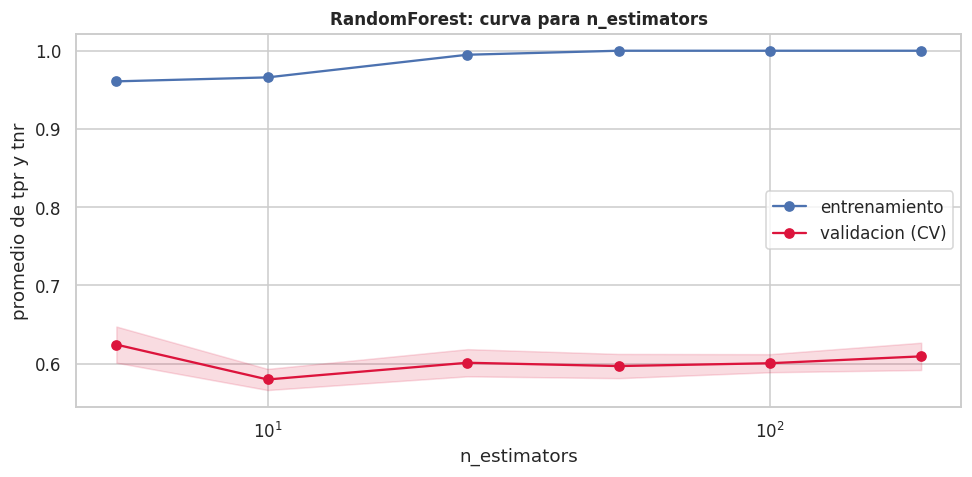


mejor n_estimators: 5


In [28]:
from sklearn.ensemble import RandomForestClassifier

ARBOLES = [5, 10, 25, 50, 100, 200]

mejor_n = curva(
    lambda n: RandomForestClassifier(n_estimators=n, class_weight="balanced",
                                     random_state=SEMILLA),
    ARBOLES, "RandomForest: curva para n_estimators", "n_estimators", log=True)

---
# 15. SVM · curva para `kernel`

`linear` separa con hiperplano, `poly` con superficie polinómica, `rbf` con frontera gaussiana.
Sobre el conjunto escalado.

  kernel=linear   train=1.000  validacion=0.746 (+/- 0.02297)
  kernel=poly     train=0.938  validacion=0.541 (+/- 0.00906)
  kernel=rbf      train=0.998  validacion=0.721 (+/- 0.01974)


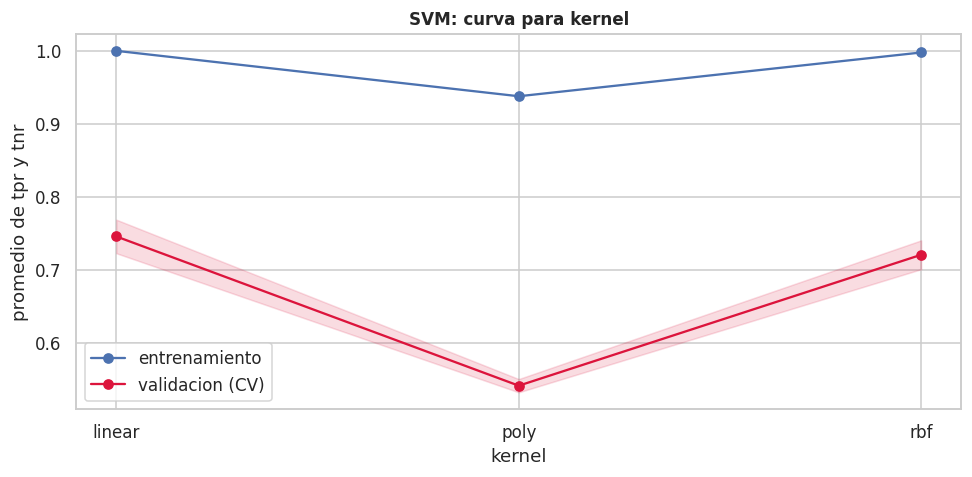


mejor kernel: linear


In [29]:
from sklearn.svm import SVC

KERNELS = ["linear", "poly", "rbf"]

mejor_kernel = curva(
    lambda k: SVC(kernel=k, class_weight="balanced", random_state=SEMILLA),
    KERNELS, "SVM: curva para kernel", "kernel", datos_tr=X_train_s)

---
# 16. CrossValidation · elección del número de iteraciones

Pocos folds: se entrena con menos datos. Muchos: cada fold valida sobre pocos espectros y la medida
se vuelve ruidosa. Se recorre `k` de 2 a 10.

  k= 2  0.614 (+/- 0.01504)
  k= 3  0.627 (+/- 0.01545)
  k= 4  0.620 (+/- 0.00754)
  k= 5  0.624 (+/- 0.02307)
  k= 6  0.632 (+/- 0.01219)
  k= 7  0.621 (+/- 0.02108)
  k= 8  0.615 (+/- 0.02348)
  k= 9  0.613 (+/- 0.02331)
  k=10  0.615 (+/- 0.02290)


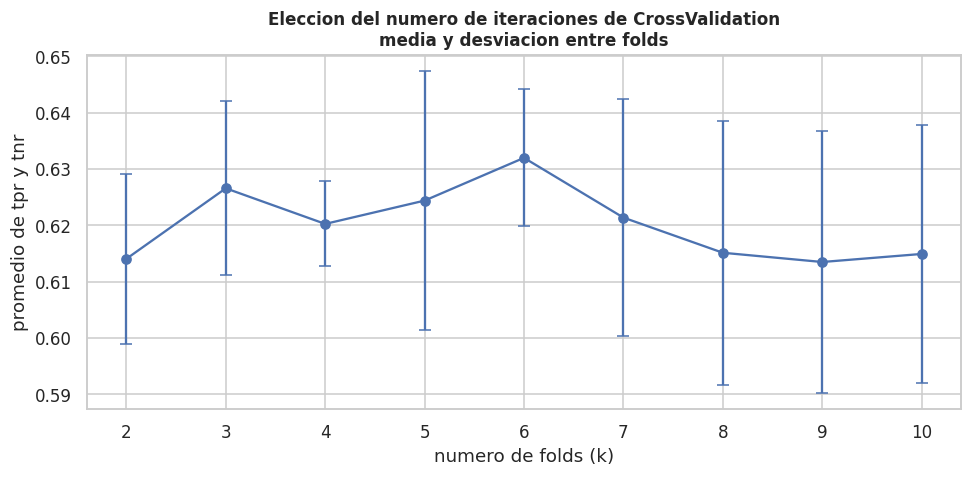


k elegido: 5


In [30]:
filas = []
for k in range(2, 11):
    est = RandomForestClassifier(n_estimators=mejor_n, class_weight="balanced",
                                 random_state=SEMILLA)
    s = cross_val_score(est, X_train, y_train, cv=folds_por_paciente(pac_de_train, k),
                        scoring=tpr_tnr)
    filas.append({"k": k, "media": np.mean(s), "desviacion": np.std(s),
                  "min": s.min(), "max": s.max()})
    print(f"  k={k:2d}  {np.mean(s):.3f} (+/- {np.std(s):.5f})")

cv_tabla = pd.DataFrame(filas).set_index("k")

plt.figure(figsize=(9, 4.5))
plt.errorbar(cv_tabla.index, cv_tabla.media, yerr=cv_tabla.desviacion,
             fmt="o-", capsize=4, color="#4C72B0")
plt.xlabel("numero de folds (k)"); plt.ylabel("promedio de tpr y tnr")
plt.title("Eleccion del numero de iteraciones de CrossValidation\n"
          "media y desviacion entre folds", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

print(f"\nk elegido: {K}")

**k = 5.** La media **no tiene tendencia**: se mueve entre 0,613 y 0,632 sin subir ni bajar con
`k`, y esas dos centésimas de rango son del mismo tamaño que la desviación entre folds. Ningún `k`
es distinguible de otro por su puntaje.

Lo que sí crece es la desviación, de 0,008 a 0,023, porque al subir `k` cada fold valida sobre menos
espectros. Se toma **5**, que deja folds de unos 600 espectros y cuesta la mitad que 10.

---
# 17. Deep learning · perceptrón multicapa

`tf.keras.Sequential` con capas `Dense`. Entrada de 6.000 bins escalados, salida de una neurona
`sigmoid`, pérdida `binary_crossentropy`.

| Nombre | Capas ocultas |
|---|---|
| MLP-3 | 64, 128, 128 |
| MLP-6 | 64, 64, 128, 128, 256, 256 |
| MLP-10 | 128 × 10 |

El conjunto de validación se aparta del entrenamiento, otra vez por paciente.

In [31]:
import tensorflow as tf
from tensorflow import keras

# conjunto de validacion apartado del entrenamiento, por paciente
pac_aj, pac_val = train_test_split(np.unique(pac_de_train), test_size=0.2, random_state=SEMILLA)
en_aj = np.isin(pac_de_train, pac_aj)

X_aj,  y_aj  = X_train_s[en_aj],  y_train[en_aj]
X_val, y_val = X_train_s[~en_aj], y_train[~en_aj]

print(f"ajuste     : {X_aj.shape}   {100*y_aj.mean():.1f}% R")
print(f"validacion : {X_val.shape}   {100*y_val.mean():.1f}% R")

ARQUITECTURAS = {
    "MLP-3  (64,128,128)":            [64, 128, 128],
    "MLP-6  (64,64,128,128,256,256)": [64, 64, 128, 128, 256, 256],
    "MLP-10 (128 x 10)":              [128] * 10,
}
EPOCHS = [5, 10, 50, 100]

def construir_red(capas):
    tf.keras.utils.set_random_seed(SEMILLA)
    model = tf.keras.Sequential(
        [tf.keras.layers.Input(shape=(X_aj.shape[1],))] +
        [tf.keras.layers.Dense(n, activation="relu") for n in capas] +
        [tf.keras.layers.Dense(1, activation="sigmoid")]
    )
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

construir_red(ARQUITECTURAS["MLP-3  (64,128,128)"]).summary()

ajuste     : (2447, 6000)   19.3% R
validacion : (611, 6000)   18.8% R


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       384,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 409,025 (1.56 MB)

 Trainable params: 409,025 (1.56 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# un experimento por arquitectura y por numero de epochs
def medir_red(model, Xd, yd):
    p = (model.predict(Xd, verbose=0).ravel() > 0.5).astype(int)
    s = np.mean(p[yd == 1] == yd[yd == 1])      # tpr
    e = np.mean(p[yd == 0] == yd[yd == 0])      # tnr
    return {"accuracy": accuracy_score(yd, p), "tpr": s, "tnr": e, "tpr_tnr": (s + e) / 2}

filas = []
for nombre, capas in ARQUITECTURAS.items():
    for ep in EPOCHS:
        model = construir_red(capas)
        model.fit(X_aj, y_aj, epochs=ep, batch_size=32, verbose=0)
        r = medir_red(model, X_val, y_val)
        filas.append({"arquitectura": nombre, "epochs": ep, **r})
        print(f"  {nombre:34s} epochs={ep:3d}  "
              f"accuracy={r['accuracy']:.3f}  tpr={r['tpr']:.3f}  tnr={r['tnr']:.3f}")

dl_tabla = pd.DataFrame(filas)

  MLP-3  (64,128,128)                epochs=  5  accuracy=0.863  tpr=0.461  tnr=0.956
  MLP-3  (64,128,128)                epochs= 10  accuracy=0.822  tpr=0.548  tnr=0.885
  MLP-3  (64,128,128)                epochs= 50  accuracy=0.849  tpr=0.504  tnr=0.929
  MLP-3  (64,128,128)                epochs=100  accuracy=0.851  tpr=0.496  tnr=0.933
  MLP-6  (64,64,128,128,256,256)     epochs=  5  accuracy=0.836  tpr=0.539  tnr=0.905
  MLP-6  (64,64,128,128,256,256)     epochs= 10  accuracy=0.851  tpr=0.478  tnr=0.938
  MLP-6  (64,64,128,128,256,256)     epochs= 50  accuracy=0.863  tpr=0.513  tnr=0.944
  MLP-6  (64,64,128,128,256,256)     epochs=100  accuracy=0.863  tpr=0.513  tnr=0.944
  MLP-10 (128 x 10)                  epochs=  5  accuracy=0.861  tpr=0.435  tnr=0.960
  MLP-10 (128 x 10)                  epochs= 10  accuracy=0.848  tpr=0.522  tnr=0.923
  MLP-10 (128 x 10)                  epochs= 50  accuracy=0.869  tpr=0.504  tnr=0.954
  MLP-10 (128 x 10)                  epochs=100  accur

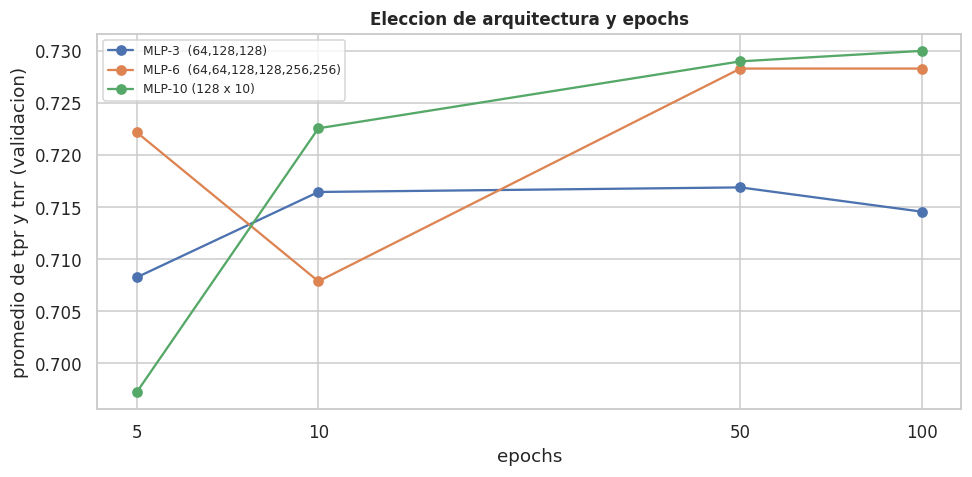

arquitectura  MLP-10 (128 x 10)  MLP-3  (64,128,128)  MLP-6  (64,64,128,128,256,256)
epochs                                                                              
5                         0.697                0.708                           0.722
10                        0.723                0.716                           0.708
50                        0.729                0.717                           0.728
100                       0.730                0.715                           0.728

arquitectura elegida : MLP-10 (128 x 10)
epochs elegidas      : 100


In [33]:
plt.figure(figsize=(9, 4.5))
for nombre, g in dl_tabla.groupby("arquitectura", sort=False):
    plt.plot(g.epochs, g.tpr_tnr, "o-", label=nombre)
plt.xscale("log"); plt.xticks(EPOCHS, EPOCHS)
plt.xlabel("epochs"); plt.ylabel("promedio de tpr y tnr (validacion)")
plt.title("Eleccion de arquitectura y epochs", fontweight="bold", fontsize=11)
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

print(dl_tabla.pivot(index="epochs", columns="arquitectura", values="tpr_tnr").round(3).to_string())

mejor_dl = dl_tabla.loc[dl_tabla.tpr_tnr.idxmax()]
CAPAS_ELEGIDAS  = ARQUITECTURAS[mejor_dl.arquitectura]
EPOCHS_ELEGIDAS = int(mejor_dl.epochs)
print(f"\narquitectura elegida : {mejor_dl.arquitectura}")
print(f"epochs elegidas      : {EPOCHS_ELEGIDAS}")

Las doce combinaciones, con el promedio de `tpr` y `tnr` en validación:

| Arquitectura | 5 | 10 | 50 | 100 |
|---|---|---|---|---|
| MLP-3, 3 capas | 0,708 | 0,716 | 0,717 | 0,715 |
| MLP-6, 6 capas | 0,722 | 0,708 | 0,728 | 0,728 |
| MLP-10, 10 capas | 0,697 | 0,723 | 0,729 | **0,730** |

Gana la de **10 capas con 100 epochs**, pero hay que mirar el rango antes de concluir nada: las doce
caben entre 0,697 y 0,730. Son **tres centésimas** entre la mejor y la peor, del mismo tamaño que la
dispersión entre folds de la sección 16.

Y las 100 epochs ganan por **una milésima** sobre las 50, que es otra diferencia indistinguible del
ruido.

Dicho de otra forma: **ni la profundidad de la red ni el número de epochs deciden el desempeño
aquí**. Doce entrenamientos para descubrir que las tres arquitecturas son equivalentes es un
resultado, no un fracaso.

---
# 18. Comparación final de los cuatro estimadores

Cada uno con su hiperparámetro ganador, entrenado sobre el 80% completo y evaluado **una sola vez**
sobre el 20% de test.

In [34]:
resultados = []

# los tres estimadores de scikit-learn
for nombre, est, Xtr, Xte in [
    ("DecisionTree", DecisionTreeClassifier(max_depth=mejor_depth, class_weight="balanced",
                                            random_state=SEMILLA),       X_train,   X_test),
    ("RandomForest", RandomForestClassifier(n_estimators=mejor_n, class_weight="balanced",
                                            random_state=SEMILLA),       X_train,   X_test),
    ("SVM",          SVC(kernel=mejor_kernel, class_weight="balanced",
                         random_state=SEMILLA),                          X_train_s, X_test_s),
]:
    est.fit(Xtr, y_train)
    resultados.append({"modelo": nombre,
                       "accuracy": accuracy_score(y_test, est.predict(Xte)),
                       "tpr": tpr(est, Xte, y_test),
                       "tnr": tnr(est, Xte, y_test)})
    print(f"  {nombre} listo")

# la red, con la arquitectura y las epochs elegidas, entrenada con todo el 80%
red = construir_red(CAPAS_ELEGIDAS)
red.fit(X_train_s, y_train, epochs=EPOCHS_ELEGIDAS, batch_size=32, verbose=0)
r = medir_red(red, X_test_s, y_test)
resultados.append({"modelo": "DeepLearning", "accuracy": r["accuracy"],
                   "tpr": r["tpr"], "tnr": r["tnr"]})
print("  DeepLearning listo")

tabla = pd.DataFrame(resultados).set_index("modelo")
BASELINE = max(y_test.mean(), 1 - y_test.mean())
print(f"\nbaseline de clase mayoritaria en test: {BASELINE:.3f} accuracy (con tpr = 0)\n")
print(tabla.round(3).to_string())

  DecisionTree listo
  RandomForest listo
  SVM listo
  DeepLearning listo

baseline de clase mayoritaria en test: 0.810 accuracy (con tpr = 0)

              accuracy    tpr    tnr
modelo                              
DecisionTree     0.829  0.626  0.877
RandomForest     0.833  0.338  0.949
SVM              0.842  0.554  0.909
DeepLearning     0.884  0.540  0.965


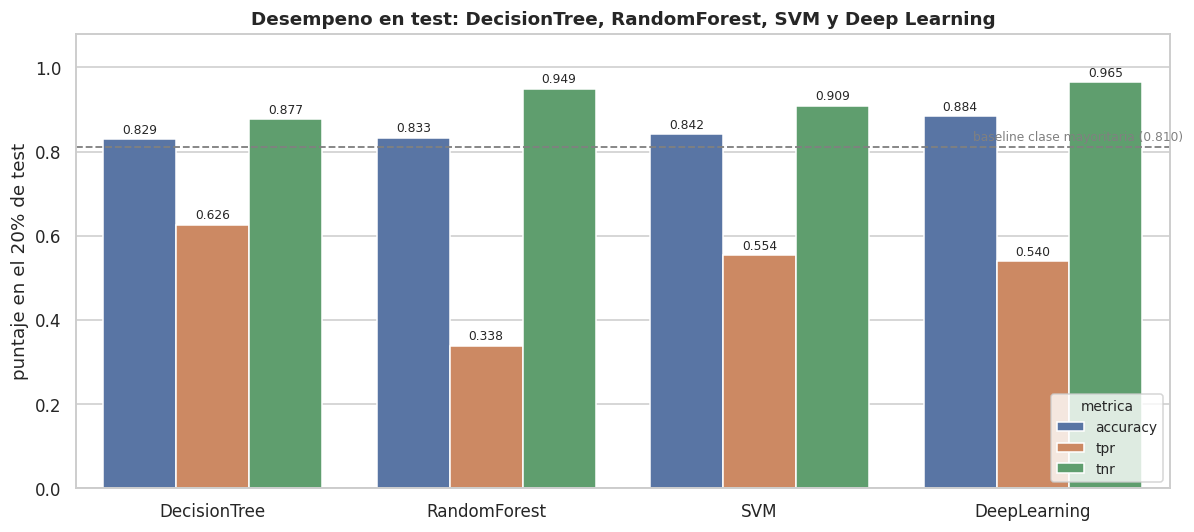

In [35]:
# ---- barplot comparativo -------------------------------------------------------------------
largo = tabla.reset_index().melt(id_vars="modelo", var_name="metrica", value_name="valor")

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=largo, x="modelo", y="valor", hue="metrica", edgecolor="white")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)

ax.axhline(BASELINE, color="gray", linestyle="--", linewidth=1.2)
ax.text(len(tabla) - 0.45, BASELINE + 0.015, f"baseline clase mayoritaria ({BASELINE:.3f})",
        ha="right", fontsize=8, color="gray")

ax.set_ylim(0, 1.08); ax.set_xlabel(""); ax.set_ylabel("puntaje en el 20% de test")
ax.set_title("Desempeno en test: DecisionTree, RandomForest, SVM y Deep Learning",
             fontweight="bold", fontsize=12)
ax.legend(title="metrica", fontsize=9, title_fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

---
# 19. Conclusiones

**La señal está en el espectro.** Los cuatro modelos detectan entre **47 y 87** de los 139
resistentes del test, lejos del cero que sacaría un modelo que ignore esa clase. Confirma la
hipótesis del `mecA` (1.3).

**Ningún modelo gana en todo.** La red tiene la mejor accuracy, 0,884, y el árbol la peor, 0,829.
Pero en `tpr` el orden casi se invierte: el árbol encuentra **87** resistentes y el bosque solo
**47**. El bosque sube su accuracy acertando susceptibles, que son el 81% del conjunto. En un
hospital el error caro es no detectar un MRSA, así que pesa el `tpr`.

**El mejor balance es la red.** Promediando `tpr` y `tnr` queda en 0,752, empatada con el árbol,
pero con 0,884 de accuracy contra 0,829.

**Dos curvas salieron planas**, la del bosque y la de los epochs: sus diferencias son menores que la
desviación entre folds, así que esos dos valores elegidos no se distinguen del azar. Queda anotado
porque cambia cómo hay que leerlos.

**La partición es por paciente** (9.2), por eso los números son más bajos que los de un split al
azar, y son los que se sostendrían con un paciente nuevo.

**Limitaciones.** La prevalencia del 19% está sesgada por `HospitalHygiene` (9.1). Y el `tpr` deja
ver que todavía se escapan resistentes.

In [36]:
print("resumen de la segunda entrega\n")
print(f"  particion 80/20 por paciente   train {len(y_train)} / test {len(y_test)}")
print(f"  max_depth (DecisionTree)       {mejor_depth}")
print(f"  n_estimators (RandomForest)    {mejor_n}")
print(f"  kernel (SVM)                   {mejor_kernel}")
print(f"  folds de CrossValidation       {K}")
print(f"  arquitectura de la red         {CAPAS_ELEGIDAS}")
print(f"  epochs                         {EPOCHS_ELEGIDAS}")
print()
print(tabla.round(3).to_string())

resumen de la segunda entrega

  particion 80/20 por paciente   train 3058 / test 732
  max_depth (DecisionTree)       5
  n_estimators (RandomForest)    5
  kernel (SVM)                   linear
  folds de CrossValidation       5
  arquitectura de la red         [128, 128, 128, 128, 128, 128, 128, 128, 128, 128]
  epochs                         100

              accuracy    tpr    tnr
modelo                              
DecisionTree     0.829  0.626  0.877
RandomForest     0.833  0.338  0.949
SVM              0.842  0.554  0.909
DeepLearning     0.884  0.540  0.965


---
---
# TERCERA PRE-SUSTENTACIÓN

Hasta aquí el problema fue supervisado: el modelo veía la etiqueta. Ahora se hace lo contrario.
Se esconde la etiqueta y se le pregunta a los datos si los grupos aparecen solos.

Escalado, reducción a 2 componentes con PCA, KMeans, DBSCAN, y las tres gráficas comparadas.

---
# 20. Escalado y reducción a dos componentes

Los 6.000 bins no se pueden graficar. Con **PCA** se proyectan a 2 componentes, que son las dos
direcciones donde los espectros más se diferencian entre sí.

Antes hay que escalar, porque PCA busca direcciones de máxima varianza y sin escalar se quedaría
con los bins de intensidad más grande solo por su magnitud. Se usa `StandardScaler`, el mismo de
la sección 12.1.

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# aqui se usan las 3.790 muestras completas: no hay train y test porque no hay etiqueta que predecir
X_escalado = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, whiten=True, random_state=SEMILLA)
X_pca = pca.fit_transform(X_escalado)

print(f"de {X.shape[1]} bins a {X_pca.shape[1]} componentes\n")
for i, v in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"  componente {i}: {100*v:.1f}% de la varianza")
print(f"  {'total':13s}: {100*pca.explained_variance_ratio_.sum():.1f}%")

de 6000 bins a 2 componentes

  componente 1: 13.0% de la varianza
  componente 2: 4.6% de la varianza
  total        : 17.6%


**Las dos componentes solo recogen el 17,6% de la varianza.** Es poco, y ya dice algo: un espectro
MALDI-TOF no se deja resumir en dos números. La información está repartida entre muchísimos bins,
no concentrada en dos direcciones.

Hay que tenerlo presente al mirar las gráficas que siguen: son una sombra del dato real, no el
dato real.

---
# 21. KMeans

`n_clusters = 2`, el número de clases del problema: resistente y susceptible.

KMeans no ve la etiqueta. Parte el plano en dos grupos buscando minimizar la distancia de cada
punto al centro de su grupo. La pregunta interesante es si esos dos grupos que encuentra solo
coinciden con resistente y susceptible.

In [38]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA)
kmeans.fit(X_pca)

tabla_km = pd.crosstab(kmeans.labels_, meta.Oxacillin,
                       rownames=["cluster"], colnames=["etiqueta real"])
print(tabla_km.to_string())
print()
for c in sorted(set(kmeans.labels_)):
    en_c = kmeans.labels_ == c
    print(f"  cluster {c}: {en_c.sum():4d} espectros, {100*y[en_c].mean():4.1f}% resistentes")
print(f"\n  prevalencia en todo el conjunto: {100*y.mean():.1f}% resistentes")

etiqueta real    R     S
cluster                 
0              293  1669
1              433  1395

  cluster 0: 1962 espectros, 14.9% resistentes
  cluster 1: 1828 espectros, 23.7% resistentes

  prevalencia en todo el conjunto: 19.2% resistentes


**Los dos clusters no son resistentes contra susceptibles.** Uno tiene 14,9% de resistentes y el
otro 23,7%, contra un 19,2% del conjunto completo. Si los grupos capturaran la resistencia, un
cluster estaría cerca del 100% y el otro cerca del 0%.

KMeans encontró dos grupos, porque se le pidieron dos y siempre los encuentra, pero lo que separa
es otra cosa: alguna diferencia de adquisición o de intensidad global del espectro.

---
# 22. DBSCAN

DBSCAN no necesita que se le diga cuántos grupos hay: los arma por densidad, y lo que no alcanza
densidad lo marca como ruido. Depende de dos valores:

| | Qué significa |
|---|---|
| `eps` | El radio del vecindario de un punto |
| `min_samples` | Cuántos vecinos debe haber dentro de ese radio para considerarlo zona densa |

Para elegirlos se recorre una rejilla y se mira qué produce cada combinación: cuántos clusters
salen y qué porcentaje queda como ruido.

In [39]:
from sklearn.cluster import DBSCAN

EPS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.8]
MIN_SAMPLES = [5, 10, 20, 50]

print("clusters encontrados / porcentaje de ruido\n")
print(f"{'eps':>5s} " + "".join(f"{f'min_samples={m}':>18s}" for m in MIN_SAMPLES))
rejilla = []
for e in EPS:
    fila = f"{e:5.1f} "
    for ms in MIN_SAMPLES:
        etiquetas = DBSCAN(eps=e, min_samples=ms).fit(X_pca).labels_
        n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
        ruido = 100 * (etiquetas == -1).mean()
        rejilla.append({"eps": e, "min_samples": ms, "clusters": n_clusters, "ruido_%": ruido})
        fila += f"{n_clusters:9d} /{ruido:6.1f}%"
    print(fila)

clusters encontrados / porcentaje de ruido

  eps      min_samples=5    min_samples=10    min_samples=20    min_samples=50
  0.1        29 /   9.3%       20 /  30.2%       16 /  78.0%        0 / 100.0%
  0.2         1 /   0.8%        2 /   3.1%        1 /  10.1%        2 /  50.1%
  0.3         1 /   0.1%        1 /   0.3%        1 /   1.7%        1 /  10.2%
  0.4         1 /   0.1%        1 /   0.1%        1 /   0.4%        1 /   2.4%
  0.5         1 /   0.0%        1 /   0.1%        1 /   0.1%        1 /   0.4%
  0.8         1 /   0.0%        1 /   0.0%        1 /   0.0%        1 /   0.0%


## 22.1 Qué valores se eligen y por qué

La rejilla **no tiene un régimen intermedio**, y eso es el resultado:

- **`eps = 0,1`**: el radio es tan chico que la nube se rompe en **20 a 29 pedazos**, con hasta 78%
  de ruido. Son fragmentos de una misma nube partida de más, no grupos.
- **`eps >= 0,3`**: todo queda en **un solo cluster** con casi nada de ruido.
- **En el borde, `eps = 0,2`**, aparecen casos con 2 clusters, pero ninguno describe el conjunto:
  con `min_samples=10` el segundo cluster tiene **9 puntos** de 3.790, y con `min_samples=50` sí
  salen dos grupos parecidos, de 1.007 y 884, pero botando el **50% de los datos** como ruido.

No hay ningún valor donde salgan dos grupos que cubran el conjunto. Eso es exactamente lo que se
ve cuando los datos son **una sola nube continua**: o se parte arbitrariamente, o no se parte.

Se eligen **`eps = 0,3`** y **`min_samples = 10`**, que dan un cluster con 13 espectros de ruido,
el 0,3%. No es una elección que descubra grupos: es la que describe honestamente la forma del
dato, una nube compacta con unos pocos puntos sueltos en el borde.

Vale notar que esos 13 **no son los mismos outliers de la sección 7**: solo 2 coinciden. Son dos
criterios distintos. El IQR marca espectros con estadísticos extremos, y DBSCAN marca puntos
geométricamente aislados en el plano de las dos componentes.

In [40]:
EPS_ELEGIDO, MIN_SAMPLES_ELEGIDO = 0.3, 10

dbscan = DBSCAN(eps=EPS_ELEGIDO, min_samples=MIN_SAMPLES_ELEGIDO)
dbscan.fit(X_pca)

n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
n_ruido = (dbscan.labels_ == -1).sum()

print(f"eps={EPS_ELEGIDO}  min_samples={MIN_SAMPLES_ELEGIDO}")
print(f"  clusters : {n_clusters}")
print(f"  ruido    : {n_ruido} espectros ({100*n_ruido/len(y):.1f}%)")
print()
print(pd.crosstab(dbscan.labels_, meta.Oxacillin,
                  rownames=["cluster (-1 = ruido)"], colnames=["etiqueta real"]).to_string())

eps=0.3  min_samples=10
  clusters : 1
  ruido    : 13 espectros (0.3%)

etiqueta real           R     S
cluster (-1 = ruido)           
-1                      1    12
 0                    725  3052


---
# 23. Las tres gráficas

El mismo plano de PCA, pintado de tres formas: con la etiqueta real, con lo que encontró KMeans y
con lo que encontró DBSCAN.

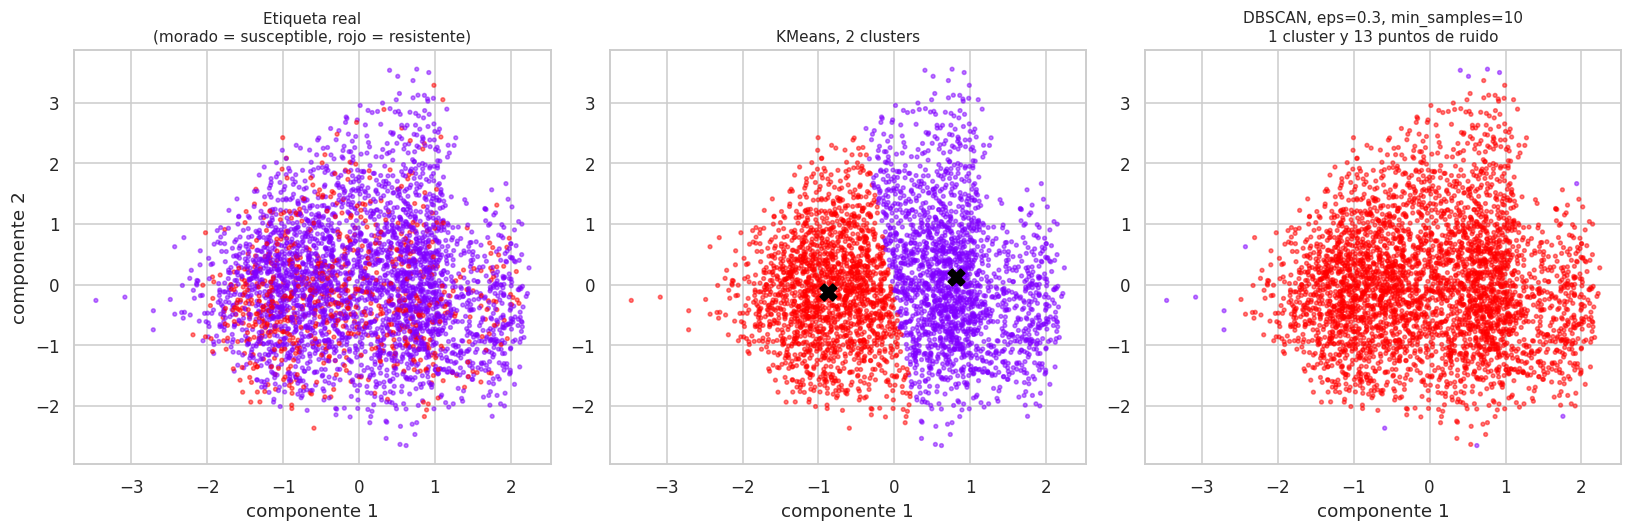

In [41]:
plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="rainbow", s=6, alpha=0.5)
plt.title("Etiqueta real\n(morado = susceptible, rojo = resistente)", fontsize=10)
plt.xlabel("componente 1"); plt.ylabel("componente 2")

plt.subplot(132)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans.labels_, cmap="rainbow", s=6, alpha=0.5)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            color="black", marker="X", s=120)
plt.title(f"KMeans, {kmeans.n_clusters} clusters", fontsize=10)
plt.xlabel("componente 1")

plt.subplot(133)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan.labels_, cmap="rainbow", s=6, alpha=0.5)
plt.title(f"DBSCAN, eps={EPS_ELEGIDO}, min_samples={MIN_SAMPLES_ELEGIDO}\n"
          f"{n_clusters} cluster y {n_ruido} puntos de ruido", fontsize=10)
plt.xlabel("componente 1")

plt.tight_layout()
plt.show()

---
# 24. Conclusiones de la tercera entrega

**Las tres gráficas cuentan la misma historia.** La de la izquierda muestra los resistentes
mezclados entre los susceptibles, sin una zona propia. KMeans parte la nube en dos mitades que no
tienen que ver con la resistencia. DBSCAN ve una sola nube.

**No hay estructura de grupos en el espectro, y menos todavía una que coincida con la
resistencia.** Esa es la respuesta del análisis no supervisado.

**Pero no contradice las entregas anteriores, las explica.** Los modelos supervisados sí detectan
entre la mitad y dos tercios de los resistentes, muy por encima del azar, así que la señal existe.
Lo que dice el clustering es que esa señal **no es la variación dominante** del espectro: está
repartida en bins concretos y queda tapada por diferencias mucho más grandes, de intensidad y de
adquisición.

Por eso el problema necesita aprendizaje supervisado. Un método no supervisado se queda con lo que
más varía, y lo que más varía en un espectro MALDI-TOF no es la resistencia.

**Y por eso las dos componentes solo recogen el 17,6%**: no hay dos direcciones que resuman un
espectro, el dato es genuinamente de alta dimensión.